# 01 — EDA: perdas de água nos municípios do Nordeste (E3 · G02)

**ODS 6 · meta 6.4.** Alvo: `alvo_t1` = IAG2013 (perdas totais na distribuição, %) em **2024**,
previsto a partir dos indicadores SINISA de **2023** (`alvo_t` = IAG2013 de 2023).

**Como reproduzir:** a partir da pasta do grupo, rode antes o pipeline
(`python -m src.pipeline --config configs/base.yaml`) e depois execute este notebook do início ao fim
(`make eda`). O notebook **não** contém lógica de preparação: ele só lê o que o pipeline gravou em
`data/processed/` e `reports/tables/`.

**Regra anti-vazamento:** toda análise que orienta decisões de modelagem usa **apenas o conjunto de
treino** (1.166 municípios). O teste (292) só aparece na checagem final do split (seção 7). A única
exceção é a seção 6 (contagem por UF), que descreve a cobertura da base inteira.

Cada visualização termina com **“O que isso muda na modelagem”**.

In [1]:
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.colors import LinearSegmentedColormap

RAIZ = Path.cwd().resolve()
if not (RAIZ / "configs").is_dir():          # executado de dentro de notebooks/
    RAIZ = RAIZ.parent
cfg = yaml.safe_load((RAIZ / "configs/base.yaml").read_text(encoding="utf-8"))
PROC = RAIZ / cfg["dados"]["processed"]
FIG = RAIZ / cfg["saidas"]["figuras"]
TAB = RAIZ / cfg["saidas"]["tabelas"]
FIG.mkdir(parents=True, exist_ok=True)

base = pd.read_csv(PROC / "base-nordeste.csv")
treino = pd.read_csv(PROC / "treino.csv")
teste = pd.read_csv(PROC / "teste.csv")
info = json.loads((PROC / "preditores.json").read_text(encoding="utf-8"))
PREDITORES = info["preditores"]
perfil = pd.read_csv(TAB / "perfil-preditores-nordeste-ref2023.csv")
NOME = dict(zip(perfil["codigo"], perfil["variavel"]))
NOME["alvo_t"] = "Perdas totais 2023 (IAG2013)"
NOME["alvo_t1"] = "Perdas totais 2024 (alvo)"

# Paleta (referência dataviz): azul = série principal, laranja = destaque, cinza = contexto
AZUL, LARANJA, CINZA = "#257de0", "#f47230", "#9c9c9c"
TEXTO, TEXTO2, GRADE = "#191919", "#666666", "#e6e6e6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": TEXTO2, "axes.edgecolor": CINZA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "xtick.color": TEXTO2, "ytick.color": TEXTO2, "text.color": TEXTO,
    "legend.frameon": False,
})
def salvar(fig, nome):
    fig.savefig(FIG / nome)
    print("figura:", (FIG / nome).relative_to(RAIZ))

print(f"base={len(base)} | treino={len(treino)} | teste={len(teste)} | preditores={len(PREDITORES)}")

base=1458 | treino=1166 | teste=292 | preditores=53


## 1. Distribuição do alvo e desbalanceamento

O alvo é contínuo (regressão), mas a decisão da E1 é um **alerta**: “perda prevista acima de um
limite”. Por isso medimos a proporção de municípios acima de limites candidatos (30, 40 e 50 %),
definidos em `configs/base.yaml → diagnostico.limites_alerta_pct`. O limite oficial ainda será
escolhido com o responsável pela decisão.

conjunto,base (% acima),treino (% acima),teste (% acima)
limite (%),,,
30.0,64.0,64.2,63.0
40.0,42.8,43.0,42.1
50.0,30.3,30.5,29.5


assimetria=0.51 | quartis=[24.6, 36.3, 54.1]
figura: reports\figures\figura-eda-01-distribuicao-alvo.png


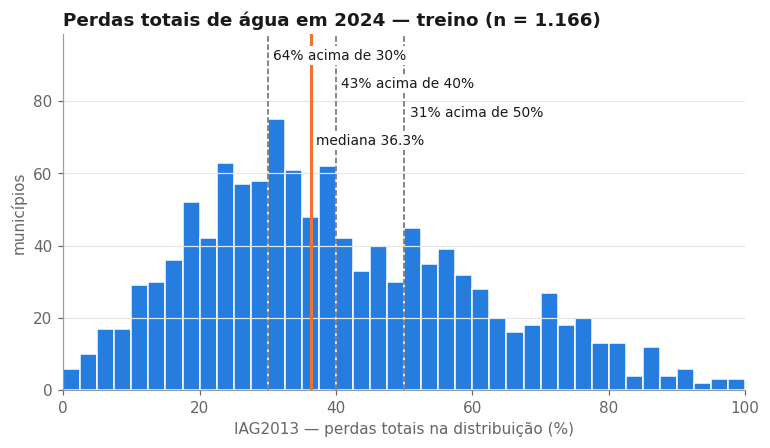

In [2]:
y = treino["alvo_t1"]
desb = pd.read_csv(TAB / "preparacao-desbalanceamento-alvo.csv")
display(desb.pivot(index="limite_pct", columns="conjunto", values="proporcao_acima_pct")
        [["base", "treino", "teste"]].rename_axis("limite (%)").add_suffix(" (% acima)"))
print(f"assimetria={y.skew():.2f} | quartis={y.quantile([.25, .5, .75]).round(1).tolist()}")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(y, bins=np.arange(0, 102.5, 2.5), color=AZUL, edgecolor="white", linewidth=1)
topo = ax.get_ylim()[1]
ax.set_ylim(0, topo * 1.25)
for k, lim in enumerate(cfg["diagnostico"]["limites_alerta_pct"]):
    p = 100 * (y > lim).mean()
    ax.axvline(lim, color=TEXTO2, linestyle="--", linewidth=1)
    ax.text(lim + 0.8, topo * (1.2 - 0.1 * k), f"{p:.0f}% acima de {lim}%", va="top",
            fontsize=9, color=TEXTO, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.axvline(y.median(), color=LARANJA, linewidth=2)
ax.text(y.median() + 0.8, topo * 0.9, f"mediana {y.median():.1f}%", va="top",
        color=TEXTO, fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.set(title="Perdas totais de água em 2024 — treino (n = 1.166)",
       xlabel="IAG2013 — perdas totais na distribuição (%)", ylabel="municípios", xlim=(0, 100))
ax.grid(axis="x", visible=False)
salvar(fig, "figura-eda-01-distribuicao-alvo.png")
plt.show()

**Leitura.** A distribuição é unimodal e levemente assimétrica à direita (assimetria ≈ 0,5; mediana
≈ 36 %, quartis ≈ 25 % e 54 %), cobre de 0 a 100 % e não tem massa concentrada em um único valor.
A proporção acima de cada limite é praticamente igual em base, treino e teste (ex.: 40 % → 42,8 /
43,0 / 42,1 %), confirmando que o split estratificado por quintis preservou a distribuição.

**O que isso muda na modelagem.** Não há desbalanceamento severo: no limite de 40 % a classe
“alerta” tem ~43 % dos municípios; mesmo no limite de 50 %, ~30 %. Mantemos **regressão com MAE**
como métrica principal e não precisamos de reamostragem/pesos. Se a E5 avaliar o alerta como
classificação derivada, ela deve usar precisão/recall (não acurácia), porque a proporção muda muito
com o limite escolhido (64 % → 30 %).

## 2. Persistência: quanto 2023 explica 2024?

A pergunta da E1 exige superar a referência que **repete a perda de 2023**. O gráfico mostra cada
município do treino; a diagonal é a previsão da persistência. Em laranja, os municípios cuja perda
mudou mais de 30 p.p. entre os anos (o mesmo critério de “salto” da auditoria E2).

MAE da persistência (treino) = 8.03 p.p. | mediana do erro = 4.68 p.p.
Pearson r = 0.779 | variação média 2024-2023 = +2.00 p.p.
saltos > 30 p.p.: 54 municípios (4.6%) respondem por 27% do erro absoluto total


figura: reports\figures\figura-eda-02-persistencia.png


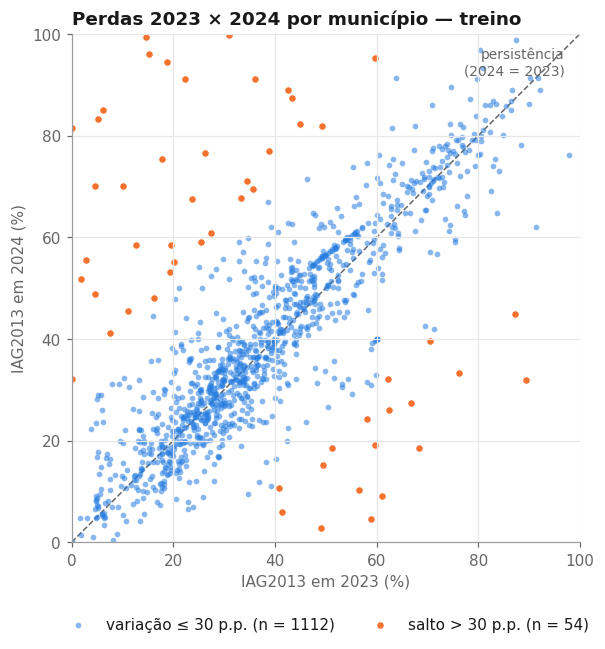

In [3]:
x, y = treino["alvo_t"], treino["alvo_t1"]
erro = (y - x).abs()
salto = erro > 30   # mesmo limite de "salto" da auditoria E2 (salto_pp)
print(f"MAE da persistência (treino) = {erro.mean():.2f} p.p. | mediana do erro = {erro.median():.2f} p.p.")
print(f"Pearson r = {np.corrcoef(x, y)[0, 1]:.3f} | variação média 2024-2023 = {(y - x).mean():+.2f} p.p.")
print(f"saltos > 30 p.p.: {salto.sum()} municípios ({100 * salto.mean():.1f}%) "
      f"respondem por {100 * erro[salto].sum() / erro.sum():.0f}% do erro absoluto total")

fig, ax = plt.subplots(figsize=(6.2, 6))
ax.plot([0, 100], [0, 100], color=TEXTO2, linewidth=1, linestyle="--", zorder=1)
ax.text(97, 92, "persistência\n(2024 = 2023)", ha="right", fontsize=9, color=TEXTO2)
ax.scatter(x[~salto], y[~salto], s=14, color=AZUL, alpha=0.55, linewidths=0,
           label=f"variação ≤ 30 p.p. (n = {(~salto).sum()})")
ax.scatter(x[salto], y[salto], s=26, color=LARANJA, edgecolors="white", linewidths=0.8,
           label=f"salto > 30 p.p. (n = {salto.sum()})")
ax.set(title="Perdas 2023 × 2024 por município — treino", xlim=(0, 100), ylim=(0, 100),
       xlabel="IAG2013 em 2023 (%)", ylabel="IAG2013 em 2024 (%)", aspect="equal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
salvar(fig, "figura-eda-02-persistencia.png")
plt.show()

**Leitura.** A perda de 2023 explica muito da de 2024 (r ≈ 0,78): a maioria dos pontos está perto
da diagonal e o erro mediano da persistência é ≈ 4,7 p.p. Mas o **MAE da persistência no treino é
≈ 8,0 p.p.**, puxado por poucos casos: 54 municípios (4,6 %) com salto > 30 p.p. concentram ~27 %
do erro absoluto. Em média as perdas subiram ≈ 2 p.p. de 2023 para 2024.

**O que isso muda na modelagem.** (1) `alvo_t` entra **sempre** como preditor e a persistência é o
baseline obrigatório da E4 — é uma referência forte e o ganho esperado do modelo é modesto.
(2) Como os saltos dominam o erro e podem ser mudança de informação (não de operação), a E4/E5 deve
reportar o MAE com e sem esses casos (sensibilidade já prevista na E2) e não usar métricas
quadráticas como principal (RMSE fica como secundária). (3) O deslocamento médio de +2 p.p. indica
que até um ajuste linear simples sobre `alvo_t` pode bater a persistência — candidato natural a
baseline interpretável.

## 3. Valores ausentes (“Não Calc.”) e por que imputar pela mediana com indicador

Na carga, textos como “Não Calc.- Dados Não Inf.” e “Não Calc.- Div/0” viram ausentes (NaN), nunca
zero. A regra da E2 (excluir preditor com > 20 % de ausentes) agora é medida **só no treino**.

figura: reports\figures\figura-eda-03-ausentes.png


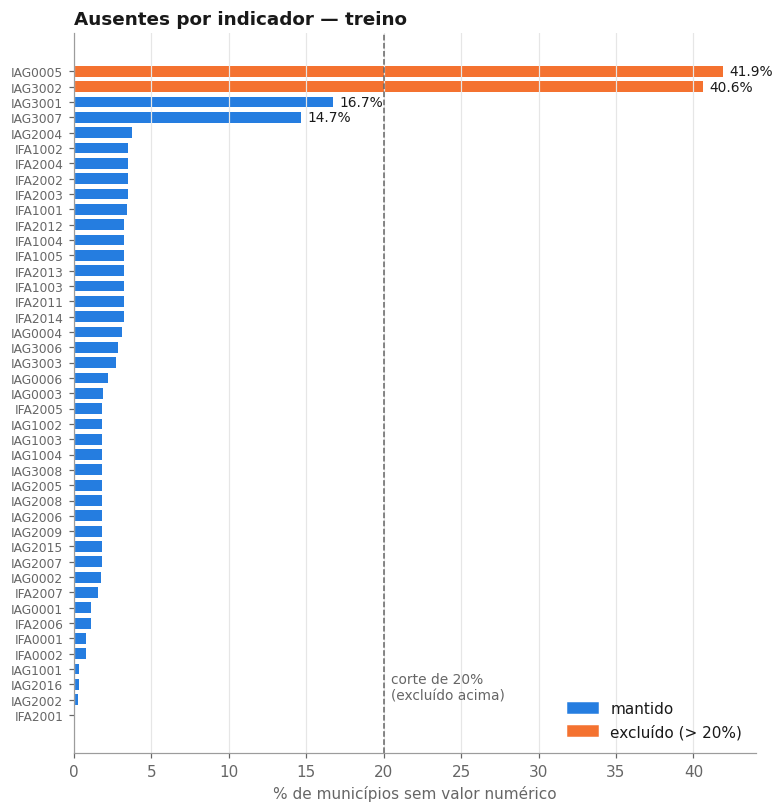

11 indicadores sem nenhum ausente no treino
IAG3001: perda mediana 2024 com valor = 34.7% | sem valor = 54.6%
IAG3007: perda mediana 2024 com valor = 34.8% | sem valor = 55.4%
UF dos municípios sem IAG3001: {'MA': 76, 'SE': 42, 'BA': 29, 'RN': 16, 'PB': 13, 'AL': 11, 'PI': 5, 'CE': 2, 'PE': 1}


In [4]:
sel = pd.read_csv(TAB / "preparacao-selecao-preditores.csv")
aus = sel[sel["ausente_treino_pct"] > 0].sort_values("ausente_treino_pct")
limite = 100 * cfg["dados"]["max_ausentes_preditor"]

fig, ax = plt.subplots(figsize=(8, 8.5))
cores = [LARANJA if not s else AZUL for s in aus["selecionado"]]
ax.barh(aus["coluna"], aus["ausente_treino_pct"], color=cores, height=0.7)
ax.axvline(limite, color=TEXTO2, linestyle="--", linewidth=1)
ax.text(limite + 0.5, 1, f"corte de {limite:.0f}%\n(excluído acima)", fontsize=9, color=TEXTO2)
for _, r in aus[aus["ausente_treino_pct"] > 10].iterrows():
    ax.text(r["ausente_treino_pct"] + 0.4, r["coluna"], f"{r['ausente_treino_pct']:.1f}%",
            va="center", fontsize=9, color=TEXTO)
ax.set(title="Ausentes por indicador — treino", xlabel="% de municípios sem valor numérico")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=AZUL, label="mantido"), Patch(color=LARANJA, label="excluído (> 20%)")],
          loc="lower right")
salvar(fig, "figura-eda-03-ausentes.png")
plt.show()

print(f"{(sel['ausente_treino_pct'] == 0).sum()} indicadores sem nenhum ausente no treino")
for c in ["IAG3001", "IAG3007"]:
    med = treino.groupby(treino[c].isna())["alvo_t1"].median()
    print(f"{c}: perda mediana 2024 com valor = {med[False]:.1f}% | sem valor = {med[True]:.1f}%")
print("UF dos municípios sem IAG3001:", treino.loc[treino["IAG3001"].isna(), "UF"].value_counts().to_dict())

**Leitura.** Só dois indicadores passam do corte (IAG0005 ≈ 42 % e IAG3002 ≈ 41 %) e são
excluídos — o mesmo resultado da E2, agora sem olhar o teste. A maioria tem até ~4 % de ausentes; 11
indicadores faltam juntos para os mesmos 21 municípios (1,8 % do treino), então parte dos
indicadores de ausência será redundante. IAG3001 (~17 %) e IAG3007
(~15 %) ficam. O achado mais importante: **a ausência não é aleatória** — municípios sem IAG3001
têm perda mediana em 2024 de ~55 %, contra ~35 % dos que informam; e a ausência se concentra em MA e
SE, UFs de perdas altas.

**O que isso muda na modelagem.** Não usamos `fillna(0)` (zero é um valor real e plausível para
vários indicadores, ex.: 0 % de setorização) nem descartamos linhas (perderíamos municípios de alta
perda, exatamente os que a decisão quer achar). Usamos **imputação pela mediana do treino** —
robusta às caudas pesadas da seção 4 — **mais um indicador binário de ausência** por coluna
(`SimpleImputer(add_indicator=True)`), para que o modelo aproveite o sinal “não informou”. Tudo
dentro do `Pipeline`, com `fit` só no treino.

## 4. Caudas pesadas e valores implausíveis

Vários indicadores têm valores extremos registrados na E2 (ex.: IFA2011 até 154.089 %, IAG2006
até 6.375 l/hab/dia). Abaixo, quatro exemplos em escala logarítmica, com os limites de recorte
(percentis 1 e 99) **aprendidos no treino** pelo `RecortePercentil`.

33 de 53 preditores têm |assimetria| > 2 no treino


,|assimetria|,indicador
IFA2014,33.6,Margem da despesa com serviço da dívida de água
IFA2012,33.5,Margem da despesa com pessoal próprio do servi...
IFA2011,33.5,Margem da despesa de exploração de água
IFA2013,33.4,Margem da despesa com pessoal total do serviço...
IAG2008,32.7,Volume de água disponibilizado para distribuiç...
IFA1005,30.6,Dias de faturamento comprometidos com contas a...
IFA2007,28.8,Despesa média de energia elétrica do serviço d...
IAG2009,27.7,Consumo total médio de água por economia


figura: reports\figures\figura-eda-04-caudas-pesadas.png


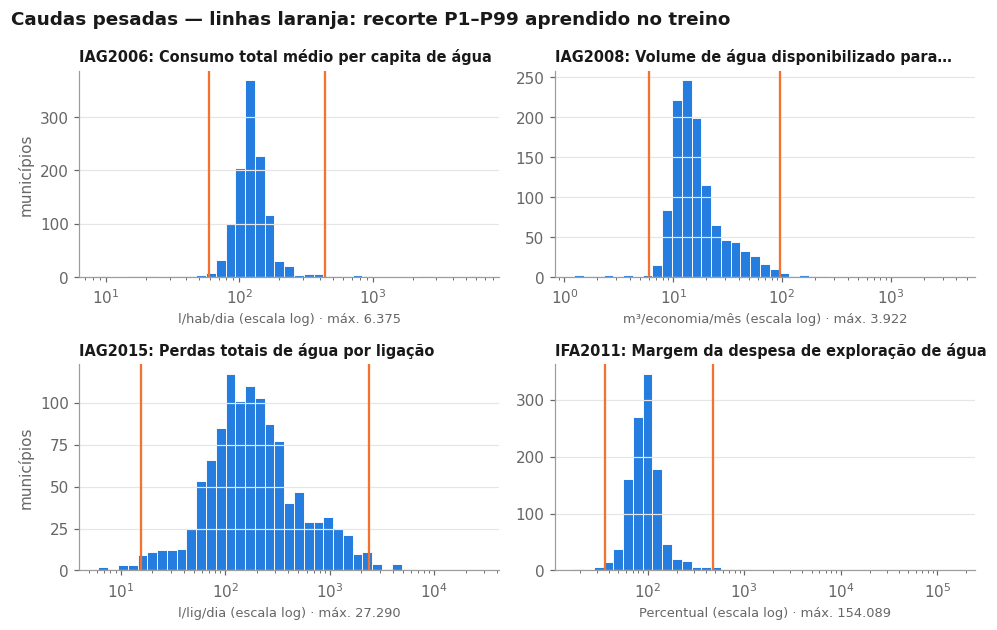

In [5]:
trat = pd.read_csv(TAB / "preparacao-tratamento-preditores.csv").set_index("preditor")
assim = treino[PREDITORES].skew().abs().sort_values(ascending=False)
print(f"{(assim > 2).sum()} de {len(PREDITORES)} preditores têm |assimetria| > 2 no treino")
display(assim.head(8).round(1).rename("|assimetria|").to_frame()
        .assign(indicador=lambda d: d.index.map(NOME)))

exemplos = ["IAG2006", "IAG2008", "IAG2015", "IFA2011"]
fig, axs = plt.subplots(2, 2, figsize=(9, 5.8))
for ax, c in zip(axs.flat, exemplos):
    v = treino[c].dropna()
    v = v[v > 0]
    bins = np.logspace(np.log10(v.min()), np.log10(v.max()), 40)
    ax.hist(v, bins=bins, color=AZUL, edgecolor="white", linewidth=0.6)
    ax.set_xscale("log")
    lo, hi = trat.loc[c, "limite_inferior_treino"], trat.loc[c, "limite_superior_treino"]
    for lim in (lo, hi):
        if lim > 0:
            ax.axvline(lim, color=LARANJA, linewidth=1.5)
    unidade = perfil.set_index("codigo").loc[c, "unidade"]
    ax.set_title(f"{c}: {textwrap.shorten(NOME[c], 44, placeholder='…')}", fontsize=9.5)
    maximo = f"{v.max():,.0f}".replace(",", ".")
    ax.set_xlabel(f"{unidade} (escala log) · máx. {maximo}", fontsize=8.5)
    ax.grid(axis="x", visible=False)
axs[0, 0].set_ylabel("municípios"); axs[1, 0].set_ylabel("municípios")
fig.suptitle("Caudas pesadas — linhas laranja: recorte P1–P99 aprendido no treino",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "figura-eda-04-caudas-pesadas.png")
plt.show()

**Leitura.** 33 dos 53 preditores têm |assimetria| > 2, e alguns chegam a ~33 (IFA2011–IFA2014,
IAG2008): poucos municípios com valores ordens de grandeza acima da mediana, frequentemente
fisicamente implausíveis (consumo per capita de milhares de l/hab/dia, margens de despesa de
100.000 %) ou negativos onde não deveriam (IAG2005, IFA1001). São, muito provavelmente, erros de
informação do prestador — mas não temos como confirmar município a município.

**O que isso muda na modelagem.** Em vez de remover municípios (a amostra já é pequena: 28 linhas
por preditor), aplicamos **winsorização P1–P99** com limites aprendidos no treino (o teste só é
recortado com os limites do treino; ver `reports/tables/preparacao-tratamento-preditores.csv`).
Não usamos log porque há zeros e negativos. Depois do recorte, **padronizamos** (`StandardScaler`)
para que modelos lineares regularizados e baseados em distância (kNN) não sejam dominados por
indicadores em R$/empregado.ano. Modelos de árvore são insensíveis a essas duas etapas, então elas
não os prejudicam.

## 5. Redundância entre indicadores de perdas e consumo

A E2 alertou que vários indicadores de 2023 medem a mesma coisa que o alvo defasado. Correlação de
**Spearman** (robusta às caudas) no treino, entre o alvo, a perda de 2023 e os indicadores de
consumo, faturamento e medição mais ligados a ela.

figura: reports\figures\figura-eda-05-correlacao.png


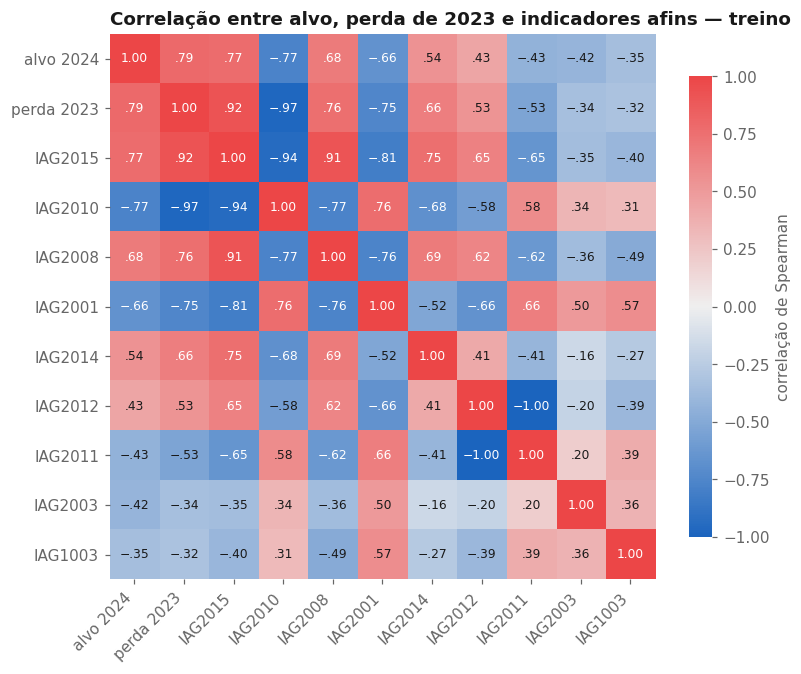

,Spearman com alvo 2024,indicador
alvo_t,0.79,Perdas totais 2023 (IAG2013)
IAG2015,0.77,Perdas totais de água por ligação
IAG2010,-0.77,Consumo de água em relação ao volume disponibi...
IAG2008,0.68,Volume de água disponibilizado para distribuiç...
IAG2001,-0.66,Micromedição de água em relação ao volume disp...
IAG2014,0.54,Perdas totais lineares de água na rede de dist...
IFA1005,0.52,Dias de faturamento comprometidos com contas a...
IAG2012,0.43,Perdas de faturamento de água


In [6]:
cols = ["alvo_t1", "alvo_t", "IAG2015", "IAG2010", "IAG2008", "IAG2001", "IAG2014",
        "IAG2012", "IAG2011", "IAG2003", "IAG1003"]
corr = treino[cols].corr(method="spearman")
rotulos = [c.replace("alvo_t1", "alvo 2024").replace("alvo_t", "perda 2023") for c in cols]

cmap = LinearSegmentedColormap.from_list("div", ["#1b64be", "#efefef", "#ec4647"])
fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
for i in range(len(cols)):
    for j in range(len(cols)):
        r = corr.values[i, j]
        ax.text(j, i, f"{r:.2f}".replace("-", "−").replace("0.", "."), ha="center", va="center",
                fontsize=8, color="white" if abs(r) > 0.6 else TEXTO)
ax.set_xticks(range(len(cols)), rotulos, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), rotulos)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("correlação de Spearman", color=TEXTO2)
cb.outline.set_visible(False)
ax.set_title("Correlação entre alvo, perda de 2023 e indicadores afins — treino")
salvar(fig, "figura-eda-05-correlacao.png")
plt.show()

top = (treino[PREDITORES + ["alvo_t1"]].corr(method="spearman")["alvo_t1"]
       .drop("alvo_t1").sort_values(key=abs, ascending=False).head(8))
display(top.round(2).rename("Spearman com alvo 2024").to_frame()
        .assign(indicador=lambda d: d.index.map(NOME)))

**Leitura.** Há blocos quase duplicados: IAG2011 e IAG2012 têm correlação −1,00 (perdas de
faturamento = complemento do volume faturado); IAG2010 (consumo / volume disponibilizado) tem −0,97
com a perda de 2023 — é praticamente o complemento dela; IAG2015 (perdas por ligação) tem 0,92.
Os preditores mais associados ao alvo são a perda de 2023 (0,79), IAG2015 (0,77) e IAG2010 (−0,77):
todos contam a mesma história.

**O que isso muda na modelagem.** Isso **não é vazamento** (tudo é de 2023), mas é colinearidade
forte. Consequências para a E4: (1) o modelo linear deve ser **regularizado** (Ridge/Lasso/ElasticNet)
— sem regularização os coeficientes desse bloco ficam instáveis e ininterpretáveis; (2) a importância
de atributos de árvores vai se “dividir” entre os indicadores redundantes, então a interpretação na
E6/E7 deve agrupar o bloco; (3) se for feita seleção de atributos para remover redundância, ela tem
que acontecer **dentro da CV** (não neste notebook), para não vazar informação dos folds de
validação.

## 6. Heterogeneidade entre UFs (subgrupos)

Visualização extra (a E3 pede cinco). O gráfico usa só o treino (n por UF no eixo); a tabela abaixo
dele mostra a **base inteira**, para registrar a cobertura de cada UF.

figura: reports\figures\figura-eda-06-alvo-por-uf.png


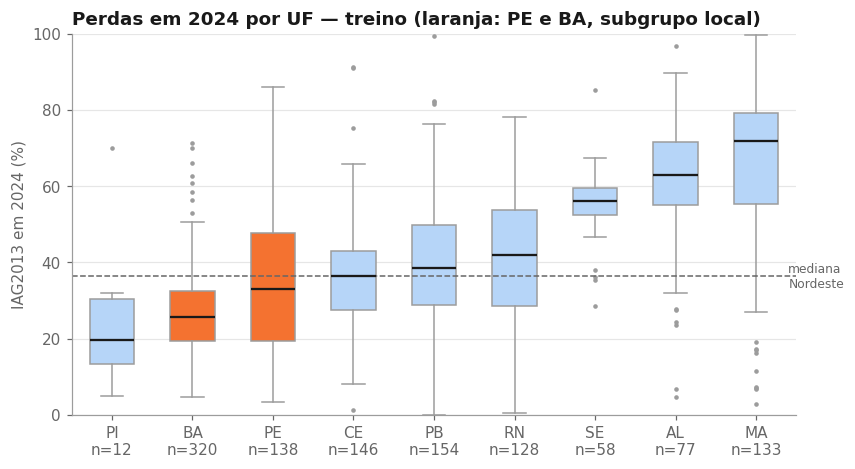

,municipios,mediana
UF,,
PI,17,20.0
BA,396,25.7
PE,176,33.6
CE,182,35.9
PB,197,38.0
RN,159,42.4
SE,75,56.0
AL,93,63.6
MA,163,70.2


In [7]:
ordem = treino.groupby("UF")["alvo_t1"].median().sort_values().index.tolist()
n_treino = treino["UF"].value_counts()
fig, ax = plt.subplots(figsize=(8.5, 4.5))
dados_uf = [treino.loc[treino["UF"] == uf, "alvo_t1"] for uf in ordem]
bp = ax.boxplot(dados_uf, vert=True, patch_artist=True, widths=0.55,
                medianprops=dict(color=TEXTO, linewidth=1.5),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=CINZA, markeredgecolor="none"),
                whiskerprops=dict(color=CINZA), capprops=dict(color=CINZA))
for patch, uf in zip(bp["boxes"], ordem):
    patch.set_facecolor(LARANJA if uf in ("PE", "BA") else "#b6d5f8")
    patch.set_edgecolor(CINZA)
ax.set_xticks(range(1, len(ordem) + 1), [f"{uf}\nn={n_treino[uf]}" for uf in ordem])
ax.axhline(treino["alvo_t1"].median(), color=TEXTO2, linestyle="--", linewidth=1)
ax.text(len(ordem) + 0.4, treino["alvo_t1"].median(), "mediana\nNordeste", fontsize=8,
        color=TEXTO2, va="center")
ax.set(title="Perdas em 2024 por UF — treino (laranja: PE e BA, subgrupo local)",
       ylabel="IAG2013 em 2024 (%)", ylim=(0, 100))
ax.grid(axis="x", visible=False)
salvar(fig, "figura-eda-06-alvo-por-uf.png")
plt.show()
display(base.groupby("UF")["alvo_t1"].agg(municipios="count", mediana="median").round(1)
        .sort_values("mediana"))

**Leitura.** As UFs são muito diferentes: BA tem mediana ≈ 26 % e MA ≈ 70 %; AL e SE também ficam
acima de 55 %. PE fica perto da mediana regional. O PI tem só 17 municípios na base (12 no treino;
cobertura de 9,4 %, já registrada na E2) e não é representativo.

**O que isso muda na modelagem.** (1) O erro tem de ser **reportado por UF e para PE+BA/RIDE**
(compromisso da E2), porque um MAE regional único pode esconder desempenho ruim em UFs de perda alta.
(2) A UF está fora dos preditores (decisão da E2, para não “penalizar pelo endereço”), mas a
diferença é grande o bastante para a E4 testar, como **análise de sensibilidade**, um modelo com UF
em one-hot — e comparar com o principal. (3) Nenhuma conclusão do projeto vale para o PI.

## 7. Checagem do split e da preparação (sem vazamento)

O pipeline ajustou o pré-processamento **só no treino**. Se isso for verdade, as colunas
padronizadas do treino têm média 0 e desvio 1 exatos, enquanto as do teste se afastam um pouco
disso; e nenhum município aparece nos dois conjuntos.

In [8]:
tp = pd.read_csv(PROC / "treino-preparado.csv")
tep = pd.read_csv(PROC / "teste-preparado.csv")
assert set(treino["cod_IBGE"]).isdisjoint(teste["cod_IBGE"]), "município em treino e teste!"
assert tp[info["colunas_preparadas"]].isna().sum().sum() == 0
assert tep[info["colunas_preparadas"]].isna().sum().sum() == 0
media_tr = tp[PREDITORES].mean().abs().max()
media_te = tep[PREDITORES].mean().abs().max()
print(f"maior |média| padronizada: treino = {media_tr:.1e} | teste = {media_te:.3f}")
print(f"colunas após preparação: {len(info['colunas_preparadas'])} "
      f"({len(PREDITORES)} preditores + {len(info['colunas_preparadas']) - len(PREDITORES)} indicadores de ausência)")
display(pd.read_csv(TAB / "preparacao-split.csv").set_index("conjunto"))

maior |média| padronizada: treino = 6.2e-16 | teste = 0.113
colunas após preparação: 94 (53 preditores + 41 indicadores de ausência)


,municipios,alvo_t1_media,alvo_t1_desvio,alvo_t1_mediana,pe_ba,ride_petrolina_juazeiro,uf_AL,uf_BA,uf_CE,uf_MA,uf_PB,uf_PE,uf_PI,uf_RN,uf_SE
conjunto,,,,,,,,,,,,,,,
base,1458,39.93,20.42,36.13,572,8,93,396,182,163,197,176,17,159,75
treino,1166,40.01,20.56,36.33,458,6,77,320,146,133,154,138,12,128,58
teste,292,39.60,19.91,35.26,114,2,16,76,36,30,43,38,5,31,17


**Resumo das decisões sustentadas por esta EDA** (registradas em `docs/decisoes-tecnicas.md`):

| Evidência | Decisão de preparação/modelagem |
| --------- | ------------------------------- |
| Fig. 1 — classe “alerta” entre 30 % e 64 % conforme o limite | Regressão + MAE; sem reamostragem; split estratificado por quintis do alvo |
| Fig. 2 — persistência forte (r ≈ 0,78; MAE ≈ 8 p.p.), saltos concentram o erro | `alvo_t` sempre como preditor; baseline de persistência; sensibilidade sem saltos/extremos |
| Fig. 3 — ausência informativa (IAG3001/IAG3007) | Mediana do treino + indicador de ausência; excluir IAG0005 e IAG3002 |
| Fig. 4 — 33/53 preditores com |assimetria| > 2, valores implausíveis | Winsorização P1–P99 do treino + padronização |
| Fig. 5 — blocos com |ρ| ≥ 0,9 | Linear regularizado; seleção de atributos só dentro da CV |
| Fig. 6 — UFs heterogêneas, PI sub-representado | Erro por UF e subgrupos; UF em one-hot só como sensibilidade |